# DOE-019
## ローカル高値・安値カウンタ基本評価
- 対象銘柄: 9984
- 実験パラメータ
    - TYPE_MA_1
        - PPF
    - PERIOD_MA_1
        - 5, 10, 15
    - GAIN_MA_1
        - 0.05, 0.10, 0.15
    - GAIN_PREDICT_MA_1
        - 0.2, 0.4, 0.6
    - FOLLOWING_MIN
        - 5, 10, 15
    - CONTRARIAN_MIN
        - 2, 5, 8
    - CONTRARIAN_MULT
        - 1, 2, 3
- 固定パラメータ
    - PERIOD_MA_2（長周期移動平均線）
        - 1200
    - LOSSCUT_SIMPLE（単純ロスカット）
        - -50
- MA1 / MA2 クロス・シグナルのエントリ・エグジット
- 評価指標
    - 収益と約定回数

In [1]:
from pathlib import Path

import pandas as pd

# === 実験番号 ===
name_doe = "doe-019"

# pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 300)

# 指定したディレクトリのPathオブジェクトを作成
dir_path = Path(f"../doe/{name_doe}")

# .glob() で .csv ファイルのリスト（イテレータ）を取得してリストに変換
list_csv_file = sorted([str(p) for p in dir_path.glob("*.csv") if p.is_file()])

# 集計対象の条件列
columns_group = [
    "TYPE_MA_1",
    "PERIOD_MA_1",
    "GAIN_MA_1",
    "GAIN_PREDICT_MA_1",
    "FOLLOWING_MIN",
    "CONTRARIAN_MIN",
    "CONTRARIAN_MULT",
]

# CSV ファイルを読み込んで結合
df = pd.concat(
    [pd.read_csv(file) for file in list_csv_file],
    ignore_index=True,
)

# 条件ごとに Profit を集計
df_total = df.groupby(columns_group, as_index=False).agg(
    Profit_Total=("Profit", "sum"),
    Profit_Median=("Profit", "median"),
    Transactions_Median=("Transactions", "median"),
)

print(df_total)
print("\n *** Past", len(list_csv_file), "days statistics ***")
print("\n△ Profit_Total Top 3")
print(df_total.nlargest(3, "Profit_Total"))
print("\n▼ Profit_Total Bottom 3")
print(df_total.nsmallest(3, "Profit_Total"))
print("\n\n△ Profit_Median Top 3")
print(df_total.nlargest(3, "Profit_Median"))
print("\n▼ Profit_Median Bottom 3")
print(df_total.nsmallest(3, "Profit_Median"))

    TYPE_MA_1  PERIOD_MA_1  GAIN_MA_1  GAIN_PREDICT_MA_1  FOLLOWING_MIN  CONTRARIAN_MIN  CONTRARIAN_MULT  Profit_Total  Profit_Median  Transactions_Median
0         PPF            5       0.05                0.2              5               2                1        -105.0          -60.0                 32.0
1         PPF            5       0.05                0.2              5               2                2         -69.0          -37.0                 34.0
2         PPF            5       0.05                0.2              5               2                3        -135.0          -35.0                 34.0
3         PPF            5       0.05                0.2              5               5                1        -156.0          -58.0                 28.0
4         PPF            5       0.05                0.2              5               5                2         -71.0          -34.0                 30.0
..        ...          ...        ...                ...            ..

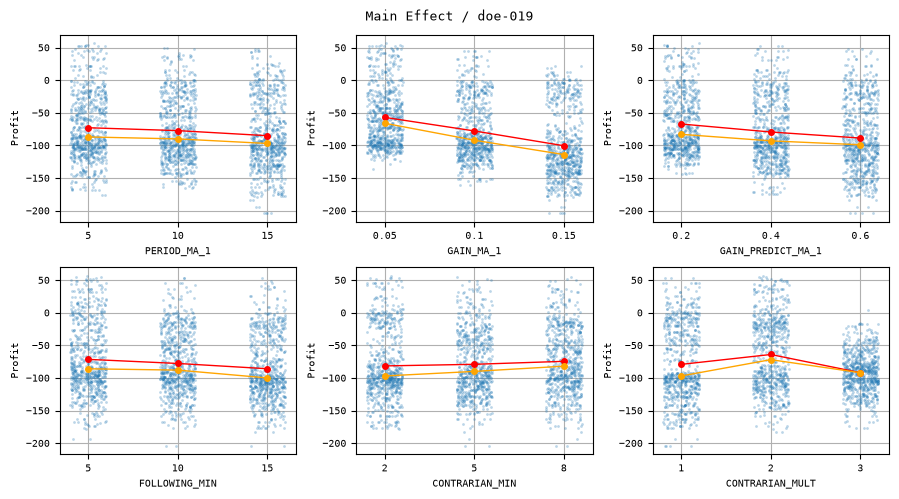

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["font.family"] = "monospace"
plt.rcParams["font.size"] = 7

cols_param = [
    "PERIOD_MA_1",
    "GAIN_MA_1",
    "GAIN_PREDICT_MA_1",
    "FOLLOWING_MIN",
    "CONTRARIAN_MIN",
    "CONTRARIAN_MULT",
]

fig, axes = plt.subplots(2, 3, figsize=(9, 5))

name_y = "Profit"
for ax, col in zip(axes.flatten(), cols_param):
    # ax.scatter(df[col], df[name_y], s=1)
    # stripplot に置き換え (jitterで横方向に散らし、alphaで透過度を調整)
    sns.stripplot(
        data=df,
        x=col,
        y=name_y,
        ax=ax,
        size=2,
        jitter=0.2,  # 横方向へのばらつき具合
        alpha=0.3,  # 重なりが見やすいよう少し透明に
        color="tab:blue",  # 散布図の色を指定
    )

    # x の各水準ごとの平均値
    mean = df.groupby(col)[name_y].mean()
    # stripplot の x 軸位置（0, 1, 2...）に合わせて線をつなぐ
    ax.plot(
        range(len(mean)),
        mean.values,
        "o-",
        color="red",
        markersize=4,
        linewidth=1,
        zorder=5,  # 点の裏に隠れないよう前面に描画
    )

    # x の各水準ごとのメジアン
    median = df.groupby(col)[name_y].median()
    # stripplot の x 軸位置（0, 1, 2...）に合わせて線をつなぐ
    ax.plot(
        range(len(median)),
        median.values,
        "o-",
        color="orange",
        markersize=4,
        linewidth=1,
        zorder=5,
    )

    ax.set(xlabel=col, ylabel=name_y)
    ax.grid(True)

fig.suptitle(f"Main Effect / {name_doe}", fontsize=9)

plt.tight_layout()
pngfile = f"../doe/{name_doe}/main_effect_{name_y}.png"
plt.savefig(pngfile)
plt.show()